<div dir="rtl" style="direction: rtl; text-align: right;">

# جلسه ۳ — PyTorch: از تنسور تا CNN

جلسه‌ی ۲ پرسپترون را با NumPy نوشتیم و دیدیم روی XOR شکست می‌خورد. امروز:

| بخش | موضوع |
|---|---|
| ۱ | تنسور: همان آرایه‌ی NumPy، با دو قابلیت اضافه |
| ۲ | autograd: مشتق‌گیری خودکار |
| ۳ | رگرسیون خطی: از حلقه‌ی دستی تا حلقه‌ی استاندارد ۵ مرحله‌ای |
| ۴ | `nn.Module`: ساخت MLP و حل XOR |
| ۵ | `Dataset` و `DataLoader`، دیتاست MNIST |
| ۶ | آموزش MLP روی MNIST |
| ۷ | CNN |
| ۸ | ذخیره‌ی مدل، GPU و خطاهای رایج |

هر جا چیزی از جلسه‌های ۱ و ۲ استفاده شده، اشاره می‌کنیم.

</div>

In [ ]:
import copy
import time

import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F

torch.manual_seed(0)
torch.backends.nnpack.set_flags(False)   # hides a harmless CPU warning on some machines
device = "cuda" if torch.cuda.is_available() else "cpu"
print("torch", torch.__version__, "| device:", device)

<div dir="rtl" style="direction: rtl; text-align: right;">

---
## بخش ۱ — تنسور

تنسور همان `ndarray` است با دو قابلیت اضافه:

1. می‌تواند روی **GPU** برود.
2. می‌تواند **گرادیان** خودش را نگه دارد.

تقریباً هر چه در NumPy بلدید (جلسه‌ی ۲) اینجا هم کار می‌کند: `shape`، برش، broadcasting، `@`. تنها فرق اسمی مهم: `axis` در PyTorch می‌شود `dim`.

</div>

In [ ]:
x = torch.tensor([[1.0, 2.0, 3.0],
                  [4.0, 5.0, 6.0]])

print(x)
print("shape :", x.shape)
print("dtype :", x.dtype)
print("device:", x.device)

print(torch.zeros(2, 3))
print(torch.randn(2, 3))                 # standard normal
print(torch.arange(5))

In [ ]:
# Same operators (same dunders!) as NumPy
w = torch.randn(3, 2)
b = torch.zeros(2)

y = x @ w + b                            # matmul + broadcasting
print(y.shape)
print(x[:, 0], x[0, 1:])                 # slicing
print(x.sum(dim=0), x.mean(dim=1))       # dim == axis
print(x.argmax(dim=1))

<div dir="rtl" style="direction: rtl; text-align: right;">

### dtype: دو نوعی که باید بشناسید

- `float32` ← ورودی‌ها و وزن‌های شبکه
- `int64` (در PyTorch: `long`) ← برچسب کلاس‌ها

تله: NumPy به‌طور پیش‌فرض `float64` می‌سازد ولی وزن‌های PyTorch `float32` هستند. اگر داده‌ی NumPy را مستقیم به مدل بدهید خطای dtype می‌گیرید. راه‌حل: `.float()`.

</div>

In [ ]:
a = np.array([[1.0, 2.0], [3.0, 4.0]])
t = torch.from_numpy(a)
print(a.dtype, "->", t.dtype)
print(t.float().dtype)

labels = torch.tensor([0, 2, 1])
print(labels.dtype)                      # int64 == long

<div dir="rtl" style="direction: rtl; text-align: right;">

### پل بین NumPy و PyTorch (یادآوری جلسه‌ی ۱: متغیر یعنی «اسم»)

`torch.from_numpy` کپی نمی‌کند؛ تنسور و آرایه **حافظه‌ی مشترک** دارند. همان داستان «دو اسم روی یک شیء». برای کپی مستقل: `.clone()`.

</div>

In [ ]:
a = np.zeros(3)
t = torch.from_numpy(a)      # shares memory with a
t[0] = 99
print("numpy array:", a)     # changed!

c = t.clone()                # independent copy
c[1] = -1
print("t:", t, "| c:", c)

back = t.numpy()             # tensor -> numpy (CPU tensors only)
print(type(back))

<div dir="rtl" style="direction: rtl; text-align: right;">

### تغییر shape

بیشترین خطاهای PyTorch خطای shape هستند. این چند تابع را باید بشناسید:

| تابع | کار |
|---|---|
| `reshape` / `view` | تغییر چیدمان با همان تعداد عنصر |
| `flatten(1)` | همه‌ی بُعدها غیر از batch را یکی می‌کند |
| `unsqueeze(d)` | یک بُعد با اندازه‌ی ۱ اضافه می‌کند |
| `squeeze()` | بُعدهای با اندازه‌ی ۱ را حذف می‌کند |
| `permute` | جابه‌جایی ترتیب بُعدها |

قرارداد PyTorch برای تصویر: **`(N, C, H, W)`** یعنی (تعداد، کانال، ارتفاع، عرض). در matplotlib و OpenCV ترتیب `(H, W, C)` است، پس برای نمایش باید `permute` کنید.

</div>

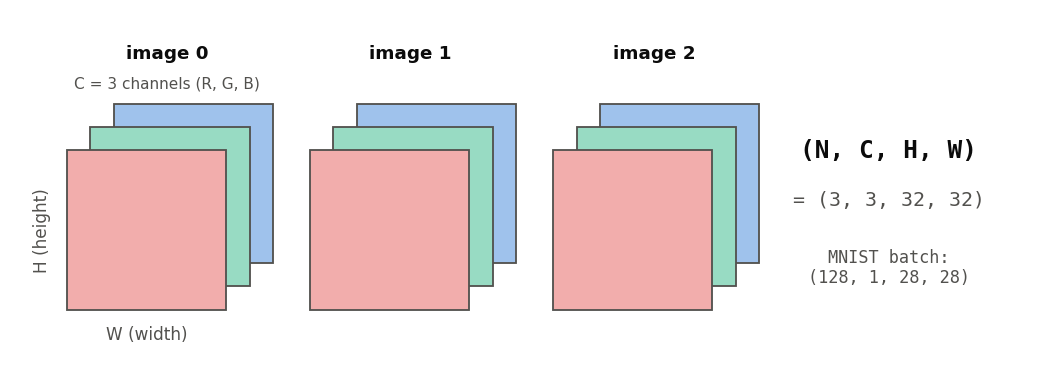

In [ ]:
batch = torch.randn(32, 1, 28, 28)               # 32 gray images
print("flatten(1)   :", batch.flatten(1).shape)   # (32, 784) for a Linear layer
print("reshape      :", batch.reshape(32, -1).shape)

img = torch.randn(28, 28)                        # a single image, no batch, no channel
print("unsqueeze x2 :", img.unsqueeze(0).unsqueeze(0).shape)   # (1, 1, 28, 28)

rgb = torch.randn(3, 64, 48)                     # (C, H, W)
print("permute      :", rgb.permute(1, 2, 0).shape)            # (H, W, C) for imshow

<div dir="rtl" style="direction: rtl; text-align: right;">

---
## بخش ۲ — autograd: مشتق‌گیری خودکار

آموزش شبکه یعنی: مشتق loss را نسبت به **همه‌ی وزن‌ها** حساب کن و وزن‌ها را کمی در خلاف جهت مشتق حرکت بده. برای شبکه‌ای با میلیون‌ها وزن، مشتق‌گیری دستی شدنی نیست.

PyTorch این کار را خودش می‌کند:

1. به تنسور می‌گویید `requires_grad=True` ← «محاسبات روی این را دنبال کن».
2. هر عملیاتی که انجام می‌دهید در یک **گراف محاسباتی** ثبت می‌شود.
3. `.backward()` با قاعده‌ی زنجیره‌ای (backpropagation) روی گراف عقب می‌رود و مشتق را در `.grad` می‌ریزد.

مثال: $y = w^2 + 2w$ پس $\frac{dy}{dw} = 2w + 2$ و در $w=3$ می‌شود ۸.

</div>

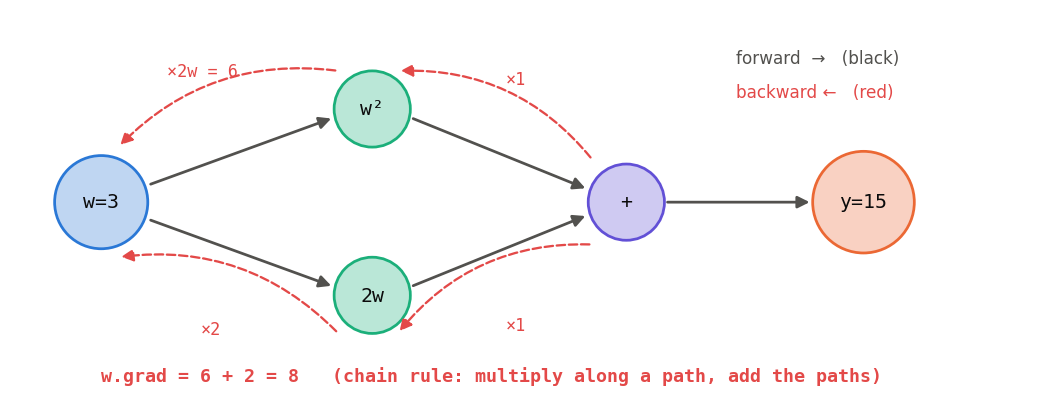

In [ ]:
w = torch.tensor(3.0, requires_grad=True)

y = w ** 2 + 2 * w       # forward pass: the graph is recorded
print("y =", y)          # note grad_fn: y remembers how it was made

y.backward()             # backward pass
print("dy/dw =", w.grad)

<div dir="rtl" style="direction: rtl; text-align: right;">

### گرادیان‌ها جمع می‌شوند

`.backward()` مقدار جدید را **جایگزین** نمی‌کند، به `.grad` قبلی **اضافه** می‌کند (همان تغییر in-place جلسه‌ی ۱). پس اگر قبل از هر بار backward آن را صفر نکنید، گرادیان‌ها روی هم تلنبار می‌شوند. دلیل وجود `optimizer.zero_grad()` همین است.

</div>

In [ ]:
w = torch.tensor(3.0, requires_grad=True)

for step in range(3):
    y = w ** 2 + 2 * w
    y.backward()
    print(f"step {step}: w.grad = {w.grad.item()}")      # 8, 16, 24 -> wrong!

w.grad.zero_()                                           # the trailing _ means in-place
y = w ** 2 + 2 * w
y.backward()
print("after zero_():", w.grad.item())

<div dir="rtl" style="direction: rtl; text-align: right;">

### خاموش‌کردن گرادیان

ثبت گراف حافظه و زمان می‌برد. موقع **ارزیابی** مدل یا **آپدیت وزن‌ها** گراف لازم نداریم. `torch.no_grad()` همان context manager جلسه‌ی ۲ است.

- `.item()` ← تنسور تک‌عنصری را به عدد پایتون تبدیل می‌کند (برای چاپ و ذخیره‌ی loss).
- `.detach()` ← همان تنسور، ولی جدا از گراف.

</div>

In [ ]:
w = torch.tensor(3.0, requires_grad=True)

y = w * 2
print(y.requires_grad)

with torch.no_grad():
    y = w * 2
print(y.requires_grad)

print((w * 2).item(), type((w * 2).item()))

<div dir="rtl" style="direction: rtl; text-align: right;">

---
## بخش ۳ — رگرسیون خطی: از دستی تا استاندارد

داده‌ای می‌سازیم که از $y = 2x + 1$ به‌اضافه‌ی نویز آمده و می‌خواهیم مدل، ۲ و ۱ را خودش پیدا کند.

</div>

In [ ]:
torch.manual_seed(0)
x = torch.linspace(-1, 1, 100).unsqueeze(1)          # (100, 1): 100 samples, 1 feature
y = 2 * x + 1 + 0.2 * torch.randn_like(x)

plt.figure(figsize=(5, 3.5))
plt.scatter(x, y, s=10)
plt.xlabel("x"); plt.ylabel("y")
plt.show()

<div dir="rtl" style="direction: rtl; text-align: right;">

### نسخه‌ی ۱: همه‌چیز دستی (فقط autograd)

چهار کار در هر تکرار: پیش‌بینی، محاسبه‌ی loss، `backward`، آپدیت وزن‌ها.

به خط آپدیت دقت کنید: `w -= lr * w.grad` (درجا). اگر بنویسید `w = w - lr * w.grad`، یک تنسور **جدید** ساخته می‌شود و اسم `w` دیگر به پارامتر اصلی اشاره نمی‌کند (بخش ۶ جلسه‌ی ۱).

</div>

In [ ]:
w = torch.randn(1, requires_grad=True)
b = torch.zeros(1, requires_grad=True)
lr = 0.1

for epoch in range(100):
    y_pred = x * w + b                       # 1. forward
    loss = ((y_pred - y) ** 2).mean()        # 2. loss (MSE)

    loss.backward()                          # 3. gradients

    with torch.no_grad():                    # 4. update (no graph needed here)
        w -= lr * w.grad
        b -= lr * b.grad
    w.grad.zero_()
    b.grad.zero_()

    if epoch % 20 == 0:
        print(f"epoch {epoch:3d} | loss {loss.item():.4f}")

print(f"w = {w.item():.3f} (true 2) | b = {b.item():.3f} (true 1)")

<div dir="rtl" style="direction: rtl; text-align: right;">

### نسخه‌ی ۲: همان کار با ابزارهای PyTorch

سه چیز را با ابزار آماده عوض می‌کنیم:

| دستی | PyTorch |
|---|---|
| `w` و `b` و `x * w + b` | `nn.Linear(1, 1)` |
| `((y_pred - y) ** 2).mean()` | `nn.MSELoss()` |
| آپدیت دستی و `zero_()` | `torch.optim.SGD` |

حلقه‌ای که به دست می‌آید **حلقه‌ی استاندارد ۵ مرحله‌ای** است. این ۵ خط را حفظ کنید؛ از رگرسیون خطی تا GPT همین است.

</div>

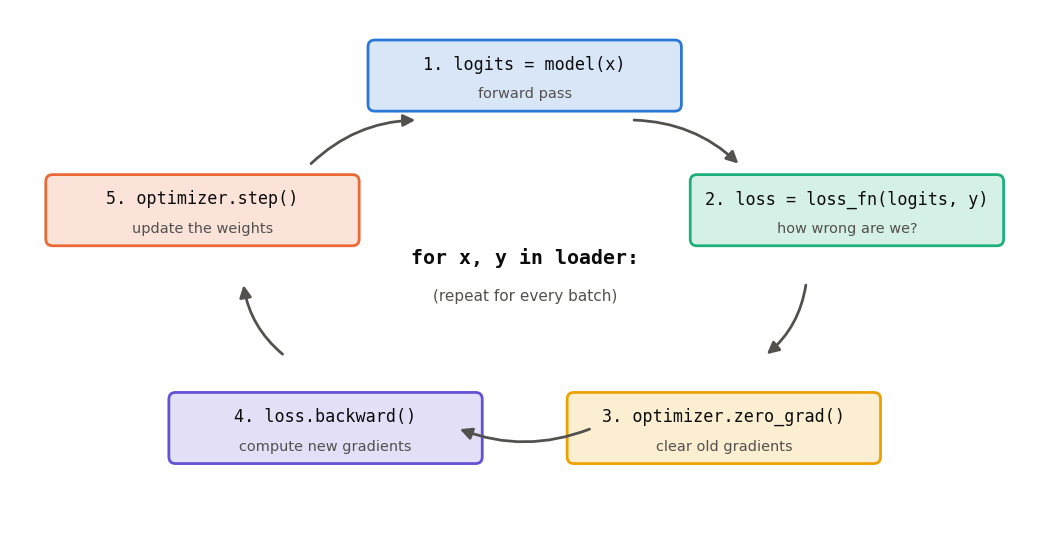

In [ ]:
model = nn.Linear(in_features=1, out_features=1)
loss_fn = nn.MSELoss()
optimizer = torch.optim.SGD(model.parameters(), lr=0.1)

for epoch in range(100):
    y_pred = model(x)                # 1. forward
    loss = loss_fn(y_pred, y)        # 2. loss
    optimizer.zero_grad()            # 3. clear old gradients
    loss.backward()                  # 4. backward
    optimizer.step()                 # 5. update the weights (in-place)

    if epoch % 20 == 0:
        print(f"epoch {epoch:3d} | loss {loss.item():.4f}")

print(f"w = {model.weight.item():.3f} | b = {model.bias.item():.3f}")

In [ ]:
plt.figure(figsize=(5, 3.5))
plt.scatter(x, y, s=10, label="data")
with torch.no_grad():
    plt.plot(x, model(x), color="red", label="model")
plt.legend()
plt.show()

<div dir="rtl" style="direction: rtl; text-align: right;">

---
## بخش ۴ — `nn.Module`: ساخت مدل خودمان

هر مدل PyTorch کلاسی است که از `nn.Module` ارث می‌برد و دو متد دارد:

- `__init__` ← لایه‌ها را **می‌سازد** (وزن‌ها اینجا به وجود می‌آیند).
- `forward` ← می‌گوید داده **چطور** از لایه‌ها رد می‌شود.

جلسه‌ی ۱ نسخه‌ی اسباب‌بازی `Module` را خودمان نوشتیم و جلسه‌ی ۲ دیدیم `__call__` و بقیه‌ی dunderها چه می‌کنند، پس این‌ها دیگر عجیب نیستند: `super().__init__()`، `model(x)` به‌جای `model.forward(x)`.

یک چیز جدید: وقتی می‌نویسید `self.fc1 = nn.Linear(...)`، `nn.Module` (با dunder دیگری به نام `__setattr__`) متوجه می‌شود و آن لایه را **ثبت** می‌کند. برای همین `model.parameters()` همه‌ی وزن‌ها را می‌شناسد.

</div>

In [ ]:
class MLP(nn.Module):
    def __init__(self, in_dim, hidden_dim, out_dim):
        super().__init__()
        self.fc1 = nn.Linear(in_dim, hidden_dim)
        self.fc2 = nn.Linear(hidden_dim, out_dim)

    def forward(self, x):
        x = torch.relu(self.fc1(x))      # hidden layer + non-linearity
        return self.fc2(x)               # raw scores (logits), no softmax here

model = MLP(in_dim=2, hidden_dim=16, out_dim=2)
print(model)

In [ ]:
# parameters() is a generator (session 2, part 2)
for name, p in model.named_parameters():
    print(f"{name:12s} {str(tuple(p.shape)):10s} requires_grad={p.requires_grad}")

n_params = sum(p.numel() for p in model.parameters())    # generator expression
print("total parameters:", n_params)

<div dir="rtl" style="direction: rtl; text-align: right;">

### حل XOR با MLP

همان داده‌ی جلسه‌ی ۲ که پرسپترون از پسش برنیامد. دو تغییر نسبت به رگرسیون:

- مسئله دسته‌بندی است، پس loss می‌شود `nn.CrossEntropyLoss`.
- برچسب‌ها باید شماره‌ی کلاس (`0` و `1`) با نوع `long` باشند.

**نکته‌ی مهم:** `CrossEntropyLoss` خودش softmax را داخلش دارد. خروجی مدل باید **logit خام** باشد. softmax گذاشتن در آخر مدل یک اشتباه رایج است.

</div>

In [ ]:
def make_data(n, centers, R, seed=0):
    rng = np.random.default_rng(seed)
    X, labels = [], []
    for i, center in enumerate(centers):
        X.append(rng.uniform(-R, R, size=(n, 2)) + center)
        labels.append(np.full(n, i))
    return np.concatenate(X), np.concatenate(labels)

centers = np.array([[1, 1], [-1, -1], [1, -1], [-1, 1]])
X_np, labels = make_data(n=50, centers=centers, R=0.75)
X_np = X_np / np.abs(X_np).max()
y_np = (labels >= 2).astype(np.int64)            # clusters 0,1 -> class 0 | clusters 2,3 -> class 1

X = torch.from_numpy(X_np).float()               # float64 -> float32
y = torch.from_numpy(y_np)                       # int64 (long)
print(X.shape, X.dtype, "|", y.shape, y.dtype)

In [ ]:
torch.manual_seed(0)
model = MLP(in_dim=2, hidden_dim=16, out_dim=2)
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.05)

losses = []
for epoch in range(200):
    logits = model(X)                    # (200, 2)
    loss = loss_fn(logits, y)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    losses.append(loss.item())

accuracy = (model(X).argmax(dim=1) == y).float().mean().item()
print(f"final loss {losses[-1]:.4f} | accuracy {accuracy:.2%}")

In [ ]:
def plot_boundary(model, X, y, title=""):
    xx, yy = np.meshgrid(np.linspace(-1.2, 1.2, 300), np.linspace(-1.2, 1.2, 300))
    grid = torch.from_numpy(np.column_stack([xx.ravel(), yy.ravel()])).float()
    with torch.no_grad():
        zz = model(grid).argmax(dim=1).reshape(xx.shape)
    plt.contourf(xx, yy, zz, alpha=0.25, cmap="bwr")
    plt.scatter(X[:, 0], X[:, 1], c=y, cmap="bwr", edgecolors="k")
    plt.title(title)

plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.plot(losses); plt.xlabel("epoch"); plt.ylabel("loss"); plt.title("training loss")
plt.subplot(1, 2, 2)
plot_boundary(model, X, y, title="MLP on XOR: solved")
plt.tight_layout()
plt.show()

<div dir="rtl" style="direction: rtl; text-align: right;">

مرز تصمیم دیگر خط راست نیست. لایه‌ی پنهان با ReLU به مدل اجازه می‌دهد مرز را خم کند.

### راه میان‌بر: `nn.Sequential`

وقتی داده فقط پشت سر هم از لایه‌ها رد می‌شود، لازم نیست کلاس بنویسید:

</div>

In [ ]:
model_seq = nn.Sequential(
    nn.Linear(2, 16),
    nn.ReLU(),
    nn.Linear(16, 2),
)
print(model_seq)
print(model_seq(X[:3]))

<div dir="rtl" style="direction: rtl; text-align: right;">

---
## بخش ۵ — `Dataset` و `DataLoader`

تا اینجا کل داده را یک‌جا به مدل دادیم. برای داده‌ی واقعی باید **batch به batch** کار کنیم.

جلسه‌ی ۲ `MyDataset` و `MyLoader` را خودمان نوشتیم. نسخه‌ی PyTorch همان است:

- `Dataset` ← کلاسی با `__len__` و `__getitem__`
- `DataLoader` ← روی دیتاست می‌چرخد، shuffle می‌کند و نمونه‌ها را در یک تنسور batch روی هم می‌چیند

</div>

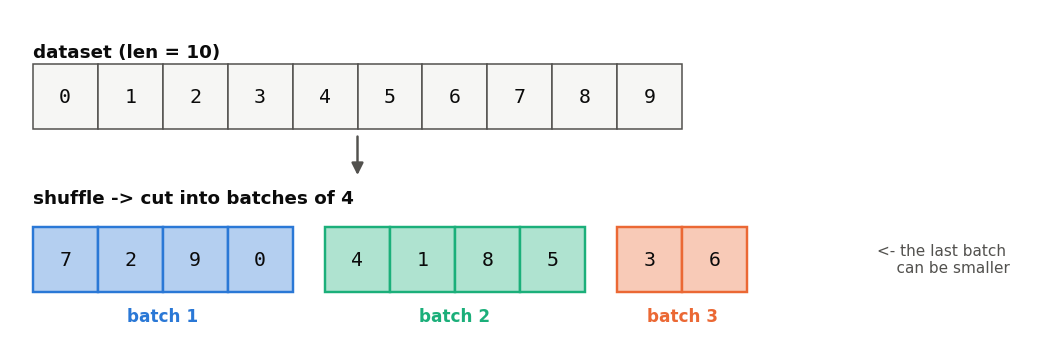

In [ ]:
from torch.utils.data import Dataset, DataLoader

class PointsDataset(Dataset):
    def __init__(self, X, y):
        self.X, self.y = X, y

    def __len__(self):
        return len(self.X)

    def __getitem__(self, i):
        return self.X[i], self.y[i]

dataset = PointsDataset(X, y)
print("len:", len(dataset))
print("dataset[0]:", dataset[0])

loader = DataLoader(dataset, batch_size=32, shuffle=True)
xb, yb = next(iter(loader))                  # iter/next from session 2
print("one batch:", xb.shape, yb.shape)
print("batches per epoch:", len(loader))

<div dir="rtl" style="direction: rtl; text-align: right;">

### MNIST

۷۰ هزار تصویر ۲۸×۲۸ سیاه‌وسفید از ارقام دست‌نویس (۶۰ هزار آموزش، ۱۰ هزار آزمون). `torchvision` آن را به‌صورت یک `Dataset` آماده دارد.

`transform` تابعی است که در `__getitem__` روی هر نمونه اعمال می‌شود (تمرین ۳ جلسه‌ی ۲). `ToTensor` تصویر را به تنسور `(1, 28, 28)` با مقادیر بین ۰ و ۱ تبدیل می‌کند.

</div>

In [ ]:
from torchvision import datasets, transforms

transform = transforms.ToTensor()
train_data = datasets.MNIST(root="data", train=True, download=True, transform=transform)
test_data = datasets.MNIST(root="data", train=False, download=True, transform=transform)

print(len(train_data), len(test_data))

image, label = train_data[0]                 # __getitem__
print(type(image), image.shape, image.dtype, "| min/max:", image.min().item(), image.max().item())
print("label:", label)

In [ ]:
fig, axes = plt.subplots(2, 8, figsize=(12, 3.5))
for i, ax in enumerate(axes.flat):
    image, label = train_data[i]
    ax.imshow(image.squeeze(), cmap="gray")  # (1,28,28) -> (28,28)
    ax.set_title(label)
    ax.axis("off")
plt.show()

In [ ]:
train_loader = DataLoader(train_data, batch_size=128, shuffle=True)
test_loader = DataLoader(test_data, batch_size=512)

xb, yb = next(iter(train_loader))
print("images:", xb.shape, xb.dtype)         # (N, C, H, W)
print("labels:", yb.shape, yb.dtype)

<div dir="rtl" style="direction: rtl; text-align: right;">

---
## بخش ۶ — آموزش MLP روی MNIST

### توابع آموزش و ارزیابی

همان حلقه‌ی ۵ مرحله‌ای، این بار داخل حلقه‌ی batchها. این دو تابع را یک بار می‌نویسیم و برای MLP و CNN هر دو استفاده می‌کنیم (مدل به‌عنوان آرگومان می‌آید).

نکته‌ها:

- `model.train()` و `model.eval()` ← بعضی لایه‌ها (Dropout، BatchNorm) در آموزش و ارزیابی رفتار متفاوتی دارند. عادت کنید همیشه بنویسید.
- `@torch.no_grad()` ← دکوراتور؛ در ارزیابی گرادیان لازم نداریم.
- `.to(device)` ← داده و مدل باید روی یک دستگاه باشند.

</div>

In [ ]:
def train_one_epoch(model, loader, loss_fn, optimizer):
    model.train()
    total_loss, correct = 0.0, 0
    for x, y in loader:
        x, y = x.to(device), y.to(device)

        logits = model(x)                # 1. forward
        loss = loss_fn(logits, y)        # 2. loss
        optimizer.zero_grad()            # 3. clear old gradients
        loss.backward()                  # 4. backward
        optimizer.step()                 # 5. update

        total_loss += loss.item() * len(x)
        correct += (logits.argmax(dim=1) == y).sum().item()
    n = len(loader.dataset)
    return total_loss / n, correct / n


@torch.no_grad()
def evaluate(model, loader, loss_fn):
    model.eval()
    total_loss, correct = 0.0, 0
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        logits = model(x)
        total_loss += loss_fn(logits, y).item() * len(x)
        correct += (logits.argmax(dim=1) == y).sum().item()
    n = len(loader.dataset)
    return total_loss / n, correct / n


def fit(model, epochs, lr=1e-3):
    model.to(device)
    loss_fn = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    history = {"train_loss": [], "test_loss": [], "train_acc": [], "test_acc": []}

    for epoch in range(1, epochs + 1):
        start = time.perf_counter()
        train_loss, train_acc = train_one_epoch(model, train_loader, loss_fn, optimizer)
        test_loss, test_acc = evaluate(model, test_loader, loss_fn)
        for key, value in zip(history, [train_loss, test_loss, train_acc, test_acc]):
            history[key].append(value)
        print(f"epoch {epoch} | train loss {train_loss:.4f} acc {train_acc:.2%} "
              f"| test loss {test_loss:.4f} acc {test_acc:.2%} | {time.perf_counter() - start:.1f} s")
    return history

<div dir="rtl" style="direction: rtl; text-align: right;">

### مدل

تصویر `(1, 28, 28)` را صاف می‌کنیم تا بردار ۷۸۴تایی شود و به لایه‌های خطی می‌دهیم. خروجی ۱۰ عدد است: یک نمره (logit) برای هر رقم.

</div>

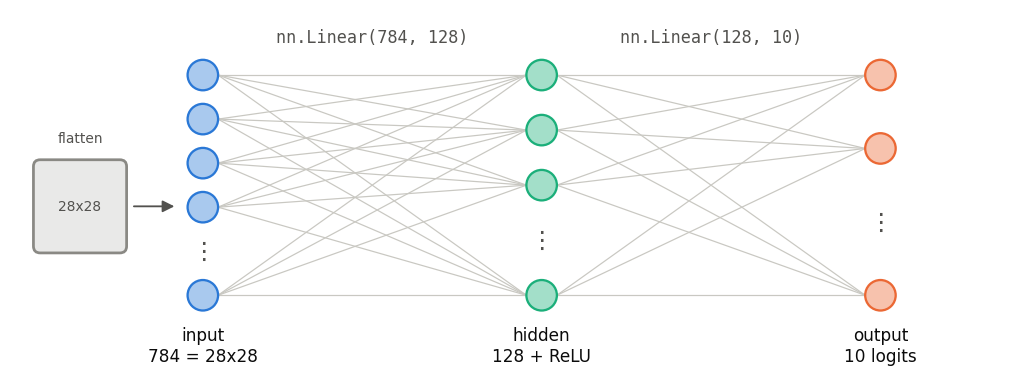

In [ ]:
class MNISTMLP(nn.Module):
    def __init__(self):
        super().__init__()
        self.flatten = nn.Flatten()              # (N,1,28,28) -> (N,784)
        self.fc1 = nn.Linear(28 * 28, 128)
        self.fc2 = nn.Linear(128, 10)

    def forward(self, x):
        x = self.flatten(x)
        x = torch.relu(self.fc1(x))
        return self.fc2(x)

def count_parameters(model):
    return sum(p.numel() for p in model.parameters())

torch.manual_seed(0)
mlp = MNISTMLP()
print(mlp)
print("parameters:", f"{count_parameters(mlp):,}")

In [ ]:
# Before training: 10 classes, random weights -> accuracy should be about 10%
print("untrained:", evaluate(mlp.to(device), test_loader, nn.CrossEntropyLoss()))

mlp_history = fit(mlp, epochs=2)

<div dir="rtl" style="direction: rtl; text-align: right;">

---
## بخش ۷ — CNN

MLP تصویر را صاف می‌کند و **ساختار مکانی** آن را دور می‌ریزد: برایش فرقی ندارد دو پیکسل کنار هم باشند یا دو سر تصویر. CNN به‌جای آن، یک **فیلتر کوچک** را روی کل تصویر می‌لغزاند.

### کانولوشن با دست

قبل از اینکه شبکه فیلتر را یاد بگیرد، خودمان یک فیلتر آشنا (Sobel، لبه‌یاب) را اعمال می‌کنیم تا ببینیم کانولوشن چه می‌کند.

</div>

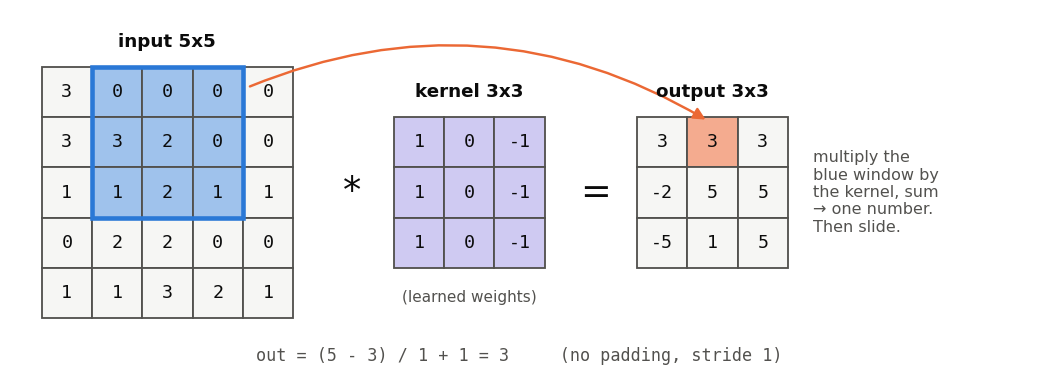

In [ ]:
image, label = train_data[0]                     # (1, 28, 28)

sobel_x = torch.tensor([[-1.0, 0.0, 1.0],
                        [-2.0, 0.0, 2.0],
                        [-1.0, 0.0, 1.0]])

# conv2d wants: input (N, C_in, H, W) and kernel (C_out, C_in, kH, kW)
inp = image.unsqueeze(0)                         # (1, 1, 28, 28)
kernel_x = sobel_x.reshape(1, 1, 3, 3)
kernel_y = sobel_x.T.reshape(1, 1, 3, 3)

edges_x = F.conv2d(inp, kernel_x)
edges_y = F.conv2d(inp, kernel_y)
print(inp.shape, "->", edges_x.shape)            # 28 -> 26: no padding

fig, axes = plt.subplots(1, 3, figsize=(9, 3))
for ax, im, title in zip(axes, [image, edges_x, edges_y], ["input", "vertical edges", "horizontal edges"]):
    ax.imshow(im.squeeze(), cmap="gray"); ax.set_title(title); ax.axis("off")
plt.show()

<div dir="rtl" style="direction: rtl; text-align: right;">

در CNN مقادیر این فیلترها **وزن‌های قابل یادگیری** هستند و شبکه خودش پیدا می‌کند چه فیلترهایی به درد می‌خورند.

### لایه‌ها و shape

`nn.Conv2d(in_channels, out_channels, kernel_size, stride=1, padding=0)`

فرمول اندازه‌ی خروجی:

$$H_{out} = \left\lfloor \frac{H_{in} + 2 \times padding - kernel}{stride} \right\rfloor + 1$$

- کانولوشن ۳×۳ با `padding=1` ← اندازه ثابت می‌ماند.
- `nn.MaxPool2d(2)` ← طول و عرض نصف می‌شود.

بهترین راه فهمیدن shape، **چاپ‌کردن** آن بعد از هر لایه است:

</div>

<div dir="rtl" style="direction: rtl; text-align: right;">

**MaxPool:** هر بلوک ۲×۲ را با بزرگ‌ترین عددش جایگزین می‌کند. وزنی ندارد که یاد بگیرد؛ فقط اندازه را نصف می‌کند تا لایه‌های بعدی ناحیه‌ی بزرگ‌تری از تصویر را «ببینند».

</div>

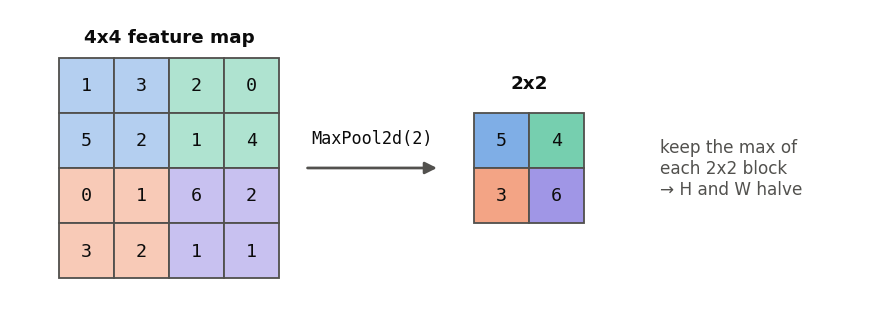

In [ ]:
x = torch.randn(8, 1, 28, 28)                    # a fake batch
layers = [
    nn.Conv2d(1, 16, kernel_size=3, padding=1),
    nn.ReLU(),
    nn.MaxPool2d(2),
    nn.Conv2d(16, 32, kernel_size=3, padding=1),
    nn.ReLU(),
    nn.MaxPool2d(2),
    nn.Flatten(),
    nn.Linear(32 * 7 * 7, 10),
]

print(f"{'input':10s} {tuple(x.shape)}")
for layer in layers:
    x = layer(x)
    print(f"{type(layer).__name__:10s} {tuple(x.shape)}")

<div dir="rtl" style="direction: rtl; text-align: right;">

عدد `32 * 7 * 7` در لایه‌ی خطی از همین‌جا می‌آید: ۳۲ کانال، هر کدام ۷×۷. اگر این عدد را اشتباه بنویسید، معروف‌ترین خطای PyTorch را می‌بینید (بخش ۸).

### مدل

</div>

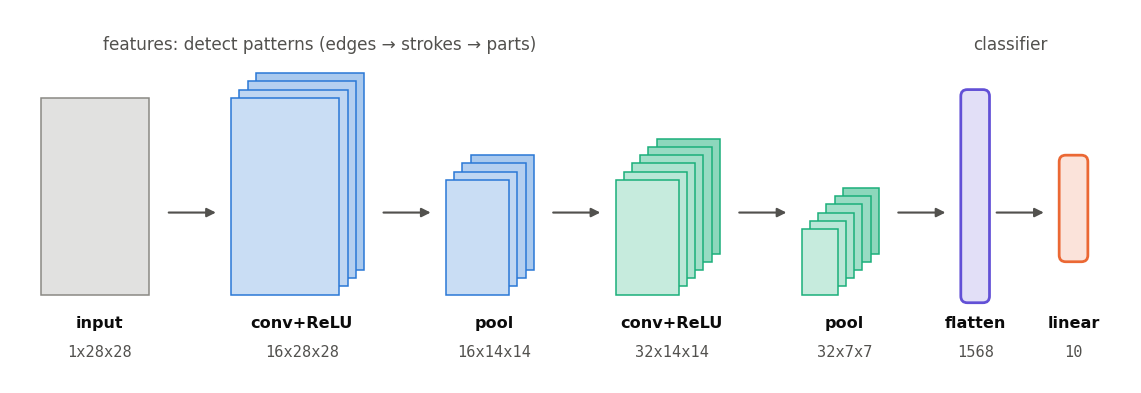

In [ ]:
class CNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 16, kernel_size=3, padding=1),   # (N, 16, 28, 28)
            nn.ReLU(),
            nn.MaxPool2d(2),                              # (N, 16, 14, 14)
            nn.Conv2d(16, 32, kernel_size=3, padding=1),  # (N, 32, 14, 14)
            nn.ReLU(),
            nn.MaxPool2d(2),                              # (N, 32, 7, 7)
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),                                 # (N, 1568)
            nn.Linear(32 * 7 * 7, 10),
        )

    def forward(self, x):
        return self.classifier(self.features(x))

torch.manual_seed(0)
cnn = CNN()
print("MLP parameters:", f"{count_parameters(mlp):,}")
print("CNN parameters:", f"{count_parameters(cnn):,}")

In [ ]:
cnn_history = fit(cnn, epochs=2)

<div dir="rtl" style="direction: rtl; text-align: right;">

### مقایسه

CNN با حدود **یک‌پنجم** پارامترهای MLP دقت بالاتری می‌گیرد، چون فیلترها در کل تصویر **مشترک** هستند (weight sharing) و ساختار مکانی تصویر حفظ می‌شود.

</div>

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
epochs = range(1, len(mlp_history["test_loss"]) + 1)

for name, history, color in [("MLP", mlp_history, "tab:blue"), ("CNN", cnn_history, "tab:red")]:
    axes[0].plot(epochs, history["train_loss"], "--", color=color, label=f"{name} train")
    axes[0].plot(epochs, history["test_loss"], "-o", color=color, label=f"{name} test")
    axes[1].plot(epochs, history["test_acc"], "-o", color=color, label=f"{name} test")

axes[0].set_title("loss"); axes[0].set_xlabel("epoch"); axes[0].legend()
axes[1].set_title("test accuracy"); axes[1].set_xlabel("epoch"); axes[1].legend()
for ax in axes:
    ax.set_xticks(list(epochs))
plt.tight_layout()
plt.show()

<div dir="rtl" style="direction: rtl; text-align: right;">

### مدل کجا اشتباه می‌کند؟

همیشه خروجی مدل را **ببینید**، نه فقط عدد دقت را.

</div>

In [ ]:
cnn.eval()
images, targets, preds = [], [], []
with torch.no_grad():
    for xb, yb in test_loader:
        images.append(xb)
        targets.append(yb)
        preds.append(cnn(xb.to(device)).argmax(dim=1).cpu())
xb, yb, preds = torch.cat(images), torch.cat(targets), torch.cat(preds)

wrong = (preds != yb).nonzero().flatten()        # indices of the mistakes
print(f"{len(wrong)} mistakes in {len(yb)} images")

fig, axes = plt.subplots(1, 8, figsize=(12, 2))
for ax, i in zip(axes, wrong):
    ax.imshow(xb[i].squeeze(), cmap="gray")
    ax.set_title(f"true {yb[i].item()} / pred {preds[i].item()}", fontsize=9)
    ax.axis("off")
plt.show()

In [ ]:
# What did the first layer learn? 16 filters of size 3x3
filters = cnn.features[0].weight.detach().cpu()  # (16, 1, 3, 3)
fig, axes = plt.subplots(2, 8, figsize=(10, 2.8))
for ax, f in zip(axes.flat, filters):
    ax.imshow(f.squeeze(), cmap="gray"); ax.axis("off")
plt.suptitle("learned filters of the first conv layer")
plt.show()

<div dir="rtl" style="direction: rtl; text-align: right;">

---
## بخش ۸ — ذخیره، GPU و خطاهای رایج

### ذخیره و بارگذاری

چیزی که ذخیره می‌کنیم `state_dict` است: یک دیکشنری از «اسم لایه ← تنسور وزن». برای بارگذاری، اول یک مدل خام از همان کلاس می‌سازیم و بعد وزن‌ها را داخلش می‌ریزیم.

</div>

In [ ]:
print(list(cnn.state_dict().keys()))

torch.save(cnn.state_dict(), "cnn_mnist.pt")

loaded = CNN()
loaded.load_state_dict(torch.load("cnn_mnist.pt"))
loaded.to(device)
print("loaded model:", evaluate(loaded, test_loader, nn.CrossEntropyLoss()))

<div dir="rtl" style="direction: rtl; text-align: right;">

یادآوری جلسه‌ی ۱: اگر می‌خواهید بهترین وزن‌ها را حین آموزش در حافظه نگه دارید، `best = model.state_dict()` کافی نیست (فقط یک اسم دیگر روی همان تنسورهاست). باید بنویسید `best = copy.deepcopy(model.state_dict())`.

### GPU

فقط یک قانون: **مدل و داده باید روی یک دستگاه باشند.**

- `model.to(device)` ← مدل را منتقل می‌کند (درجا).
- `x = x.to(device)` ← برای تنسور یک نسخه‌ی **جدید** برمی‌گرداند، پس حتماً باید دوباره به اسم نسبت بدهید.
- برای رسم یا تبدیل به NumPy: `.cpu()`.

در Colab: منوی Runtime ← Change runtime type ← GPU.

### خطاهای رایج

این‌ها را عمداً تولید می‌کنیم تا وقتی در کد خودتان دیدید، بشناسیدشان.

</div>

In [ ]:
# 1. Shape mismatch: the most common PyTorch error
layer = nn.Linear(784, 10)
x = torch.randn(32, 1, 28, 28)
try:
    layer(x)                             # forgot to flatten
except RuntimeError as e:
    print("RuntimeError:", e)

print("fixed:", layer(x.flatten(1)).shape)

In [ ]:
# 2. Wrong label dtype for CrossEntropyLoss (labels must be long, not float)
logits = torch.randn(4, 10)
labels = torch.tensor([1.0, 0.0, 3.0, 9.0])
try:
    nn.CrossEntropyLoss()(logits, labels)
except RuntimeError as e:
    print("RuntimeError:", e)

print("fixed:", nn.CrossEntropyLoss()(logits, labels.long()).item())

In [ ]:
# 3. float64 data from NumPy into a float32 model
layer = nn.Linear(3, 1)
x_np = np.random.rand(5, 3)              # float64
try:
    layer(torch.from_numpy(x_np))
except RuntimeError as e:
    print("RuntimeError:", e)

print("fixed:", layer(torch.from_numpy(x_np).float()).shape)

In [ ]:
# 4. Silent bug: (N,1) predictions vs (N,) targets -> broadcasting to (N,N)
pred = torch.zeros(4, 1)
target = torch.ones(4)
print("wrong shape:", (pred - target).shape)
print("right shape:", (pred.squeeze(1) - target).shape)

<div dir="rtl" style="direction: rtl; text-align: right;">

**چک‌لیست وقتی مدل یاد نمی‌گیرد**

1. `shape` و `dtype` ورودی، خروجی و برچسب را چاپ کنید.
2. `optimizer.zero_grad()` را فراموش نکرده‌اید؟
3. در آخر مدل softmax نگذاشته‌اید؟ (`CrossEntropyLoss` خودش دارد.)
4. نرخ یادگیری خیلی بزرگ یا خیلی کوچک نیست؟
5. مدل و داده روی یک `device` هستند؟
6. اول روی **یک batch** امتحان کنید: مدل باید بتواند آن را حفظ کند (loss نزدیک صفر). اگر نتوانست، باگ دارید.

---
## جمع‌بندی سه جلسه

برگردیم به کدی که اول جلسه‌ی ۱ دیدیم. حالا هر خطش را می‌شناسید:

</div>

```python
class Net(nn.Module):                     # inheritance
    def __init__(self):
        super().__init__()                # parent sets up parameter registration
        self.fc1 = nn.Linear(784, 128)    # callable objects that hold weights
        self.fc2 = nn.Linear(128, 10)

    def forward(self, x):
        return self.fc2(torch.relu(self.fc1(x)))

model = Net()
optimizer = torch.optim.SGD(model.parameters(), lr=0.1)   # generator of weight tensors

for epoch in range(5):
    for x, y in loader:                   # __iter__ + lazy batches + unpacking
        logits = model(x)                 # __call__ -> forward
        loss = loss_fn(logits, y)
        optimizer.zero_grad()             # gradients accumulate in-place -> reset
        loss.backward()                   # autograd fills .grad
        optimizer.step()                  # weights updated in-place

with torch.no_grad():                     # context manager: __enter__ / __exit__
    acc = (model(x_test).argmax(dim=1) == y_test).float().mean()
```

<div dir="rtl" style="direction: rtl; text-align: right;">

## تمرین

1. **autograd:** برای $y = \sin(w) \cdot w^2$ در $w = 1.5$ مشتق را با `backward` حساب کنید و با فرمول دستی مقایسه کنید.
2. **MLP:** در `MNISTMLP` یک لایه‌ی پنهان دیگر اضافه کنید (۷۸۴ ← ۲۵۶ ← ۶۴ ← ۱۰). تعداد پارامتر و دقت چه تغییری می‌کند؟
3. **بدون غیرخطی:** `torch.relu` را از MLP مسئله‌ی XOR حذف کنید و مرز تصمیم را رسم کنید. چرا دوباره خط راست شد؟
4. **CNN:** بعد از `Flatten` یک `nn.Dropout(0.3)` اضافه کنید. حالا اگر `model.eval()` را در `evaluate` بردارید چه می‌شود؟
5. **shape:** اگر `padding=1` را از هر دو لایه‌ی کانولوشن بردارید، عدد ورودی لایه‌ی خطی چند باید باشد؟ اول با فرمول حساب کنید، بعد با چاپ shape چک کنید.
6. **overfit روی یک batch:** فقط یک batch از `train_loader` بردارید و CNN را ۲۰۰ بار روی همان آموزش بدهید. loss باید به نزدیک صفر برسد.
7. **دیتاست دیگر:** `datasets.MNIST` را با `datasets.FashionMNIST` عوض کنید (هیچ چیز دیگری لازم نیست تغییر کند) و MLP و CNN را مقایسه کنید.

</div>